# The interview room, with the one-slide answer and the guesstimate spoken: what does it sound like?

**Week 4, Tuesday, chapter 10, the case's last chapter.** It applies the one-slide answer:
claim, evidence, caveat, action (concept notebook 01), defending under challenge: restate,
answer, concede, what would change your mind (concept notebook 03), and the guesstimate:
clarify, map, calculate, validate (concept notebook 06). Notebooks 04, 05 and 08 computed the
case's numbers; notebook 09 checked the page. This notebook recomputes the numbers a
hire-grade answer in `extras/C2_W04_D02_interview_room_STUDENT.md` says aloud from the day's
tables, so you can say each one under a follow-up, and draws your own score on the room's
seven criteria. Two numbers come from Monday's zone tables, which this day does not copy: the
outer zones' share of the idle money (74 percent) and their median wait (6.6 minutes before,
about 6 after), recounted when the day's data was built.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.* The coding-assistant company in the third transcript is invented.

**Who needs the answer.** You, in a screen that asks for a two-minute recommendation or a
number from nothing, and the interviewer, who follows up on any number you cannot rebuild.

**The metric at stake.** The numbers a candidate speaks: Rs 314 to Rs 260 per peak online
hour, about 5,000 to 5,700 drivers at the evening peak, and a retained share of suggested
code.

**The questions on the way.**

1. Do transcript 1's numbers hold, recounted from the case's table?
2. Do transcript 2's numbers hold, and how far off is the weak answer?
3. Do transcript 2's follow-up numbers hold?
4. Does each hire-grade answer keep its structure?
5. What does the AI-company variant's arithmetic say?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

weeks = pd.read_csv("../data/C2_W04_D02_twelve_weeks_STUDENT.csv")     # the city, week by week
groups = pd.read_csv("../data/C2_W04_D02_driver_groups_STUDENT.csv")   # drivers there before, and the 140 joiners
segments = pd.read_csv("../data/C2_W04_D02_driver_segments_STUDENT.csv")  # the idle tail, the other 880, the joiners
check("twelve weeks, three driver groups and five segment rows", len(weeks) == 12 and len(groups) == 3
      and len(segments) == 5)
print(groups.to_string(index=False))
print(segments.to_string(index=False))

PASS twelve weeks, three driver groups and five segment rows
window                           group  driver_weeks  peak_online_hours  peak_trips  peak_bookings_rs
before drivers there before the launch          6360             118000      224200          36993000
 after drivers there before the launch          6360             144000      227240          37494600
 after                 the 140 joiners           140               2300        3660            603900
                                  segment window  drivers  peak_online_hours  peak_trips
                            the idle tail before      180              20000       38000
                            the idle tail  after      180              42000       33440
the other drivers there before the launch before      880              98000      186200
the other drivers there before the launch  after      880             102000      193800
                          the 140 joiners  after      140               2300        36

## Do transcript 1's numbers hold, recounted from the case's table?

The hire-grade answer says an online hour brought in Rs 260 of fares, down from Rs 314, at the
same Rs 165 fare, and meets the follow-up it expects: bookings per driver-week rose 0.8
percent: longer weeks, mostly the other 880 drivers there before the launch working about 4
percent more hours at an unchanged Rs 313.5 an hour, while the 180 who accept least doubled
their online hours, to about 39 a week, for 12 percent fewer trips.

**Predict before you run.** The interviewer asks how per driver-week can rise while per hour
falls. Which number answers it?

a) The fare, which rose after the launch
b) Hours per driver-week, which rose by about four
c) The 140 joiners, who earned more than the rest
d) The monsoon, which ended inside the window

        rs_per_hour   fare  rs_per_driver_week  hours_per_driver_week
window                                                               
before        313.5  165.0              5816.5                   18.6
after         260.4  165.0              5861.3                   22.5
per hour -16.9 percent; per driver-week +0.8 percent
PASS Rs 314 to Rs 260 at the same Rs 165 fare
PASS about four more hours a driver-week
the idle tail: 18.5 hours a week before, 38.9 after; trips -12%
PASS the idle tail doubled its hours, to about 39 a week
PASS and completed 12 percent fewer trips
bookings per driver-week: the other 880 +4%, the idle tail -12%
PASS the rise sits with the other 880, whose weeks rose 4 percent
PASS the idle tail's weeks earned 12 percent less
PASS the joiners sit below the after average, so they pulled it down


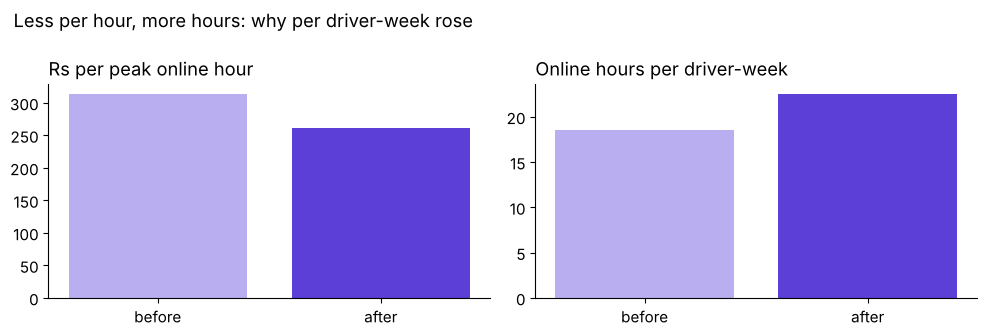

In [2]:
w = weeks.groupby("window")[["peak_online_hours", "peak_trips", "peak_bookings_rs", "active_driver_weeks"]].sum()
w = w.loc[["before", "after"]]
w["rs_per_hour"] = w.peak_bookings_rs / w.peak_online_hours
w["rs_per_driver_week"] = w.peak_bookings_rs / w.active_driver_weeks
w["hours_per_driver_week"] = w.peak_online_hours / w.active_driver_weeks
w["fare"] = w.peak_bookings_rs / w.peak_trips
change = (w.loc["after"] / w.loc["before"] - 1) * 100
print(w[["rs_per_hour", "fare", "rs_per_driver_week", "hours_per_driver_week"]].round(1).to_string())
print(f"per hour {change.rs_per_hour:+.1f} percent; per driver-week {change.rs_per_driver_week:+.1f} percent")
joiners = groups[groups.group == "the 140 joiners"].iloc[0]
check("Rs 314 to Rs 260 at the same Rs 165 fare", w.rs_per_hour.round(0).tolist() == [314, 260] and w.fare.round(0).nunique() == 1)
check("about four more hours a driver-week", round(w.hours_per_driver_week.diff().iloc[-1]) == 4)
tail = segments[segments.segment == "the idle tail"].set_index("window")
tail_week = tail.peak_online_hours / (tail.drivers * 6)                # hours a driver a week, six weeks a window
tail_trips = tail.peak_trips["after"] / tail.peak_trips["before"] - 1
print(f"the idle tail: {tail_week['before']:.1f} hours a week before, {tail_week['after']:.1f} after; "
      f"trips {tail_trips:+.0%}")
check("the idle tail doubled its hours, to about 39 a week", round(tail_week["after"]) == 39
      and 2 < tail_week["after"] / tail_week["before"] < 2.2)
check("and completed 12 percent fewer trips", round(tail_trips * 100) == -12)
seg = segments.set_index(["segment", "window"])
per_week = seg.peak_trips * 165 / (seg.drivers * 6)                   # bookings per driver-week, six weeks a window
others = "the other drivers there before the launch"
others_change = per_week[(others, "after")] / per_week[(others, "before")] - 1
tail_change = per_week[("the idle tail", "after")] / per_week[("the idle tail", "before")] - 1
print(f"bookings per driver-week: the other 880 {others_change:+.0%}, the idle tail {tail_change:+.0%}")
check("the rise sits with the other 880, whose weeks rose 4 percent", round(others_change * 100) == 4)
check("the idle tail's weeks earned 12 percent less", round(tail_change * 100) == -12)
check("the joiners sit below the after average, so they pulled it down",
      joiners.peak_bookings_rs / joiners.driver_weeks < w.loc["after", "rs_per_driver_week"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(["before", "after"], w.rs_per_hour, color=[LILAC, VIOLET])
axes[0].set_title("Rs per peak online hour", loc="left")
axes[1].bar(["before", "after"], w.hours_per_driver_week, color=[LILAC, VIOLET])
axes[1].set_title("Online hours per driver-week", loc="left")
fig.suptitle("Less per hour, more hours: why per driver-week rose", x=0.02, ha="left")
fig.tight_layout()
plt.show()

**What happened.** The answer is b: 18.6 hours a driver-week before and 22.5 after, so per
driver-week rose while per hour fell 17 percent, with the fare flat at Rs 165. Most of the
extra hours were the idle tail's: its 180 drivers went from about 18.5 hours a week to about
39 while their trips fell 12 percent, so their weeks brought in 12 percent less in fares. The rise itself
sits with the other 880, whose weeks rose 4 percent on 4 percent more hours at an unchanged
rate per hour. The 140 joiners pulled the read down, which is why the answer says so before
anyone asks.

## Do transcript 2's numbers hold, and how far off is the weak answer?

The hire-grade answer: about 8,330 trips an hour, divided by 1.68 trips per online
driver-hour, times 1.15 for the busiest half hour, is about 5,700; like for like, 0.53 online
driver-hours per trip against the chain's 0.60 says about 5,000. The weak answer divides a
day's 1 lakh trips by 2.4 and says about 41,700.

**Predict before you run.** About how many times the hire-grade 5,700 is the weak 41,700?

a) About 2 times
b) About 4 times
c) About 7 times
d) About 20 times

the chain: 8,333 / 1.68 x 1.15 = about 5,700
checked at the case's 1.90 trips an hour: about 5,000
the weak answer: about 41,700, about 7 times the chain
PASS about 5,700 by the chain
PASS about 5,000 checked like for like
PASS the weak answer is about seven times the chain


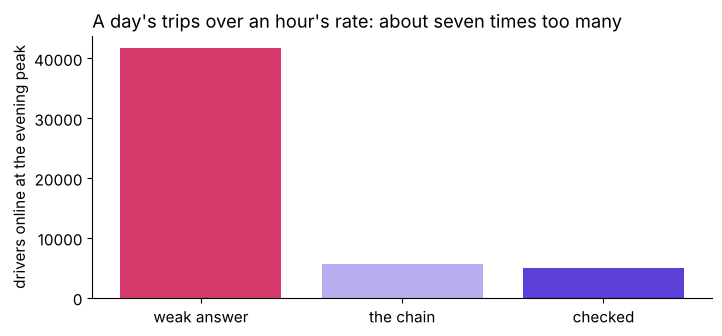

In [3]:
trips_an_hour = 10_000_000 * 0.01 * 0.25 / 3
per_driver = 2.4 * (1 - 0.30)
chain = trips_an_hour / per_driver * 1.15
weak = 10_000_000 * 0.01 / 2.4
before = w.loc["before"]
checked = trips_an_hour / (before.peak_trips / before.peak_online_hours) * 1.15
print(f"the chain: {trips_an_hour:,.0f} / {per_driver:.2f} x 1.15 = about {round(chain, -2):,.0f}")
print(f"checked at the case's {before.peak_trips / before.peak_online_hours:.2f} trips an hour: about {round(checked, -2):,.0f}")
print(f"the weak answer: about {round(weak, -2):,.0f}, about {weak / chain:.0f} times the chain")
check("about 5,700 by the chain", round(chain, -2) == 5700)
check("about 5,000 checked like for like", round(checked, -2) == 5000)
check("the weak answer is about seven times the chain", round(weak / chain) == 7)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(["weak answer", "the chain", "checked"], [weak, chain, checked], color=[ROSE, LILAC, VIOLET])
ax.set_ylabel("drivers online at the evening peak")
ax.set_title("A day's trips over an hour's rate: about seven times too many", loc="left")
plt.show()

**What happened.** The answer is c: about 41,700 against about 5,700, seven times as many. The
chain checks out at about 5,700, and at the case's 1.90 trips an hour it gives about 5,000, so
the answer says 5,000 to 5,700, inside the 2,900 to 8,600 that trips per person sets.

## Do transcript 2's follow-up numbers hold?

Two follow-ups carry numbers. The idle share, read like for like from the case's trips per
hour and a 25-minute trip, is about 0.21 before the launch and 0.34 after. A four-hour window
leaves the busiest half hour where it was: the average hour falls to about 6,250 trips, the
buffer rises to about 1.53, and the answer stays about 5,700. Each costs the evening money:
every thousand drivers held online for three hours with no trip costs up to Rs 9 lakh at the
Rs 300 floor.

**Predict before you run.** With a fourth hour that adds no trips, what happens to the drivers
needed at the busiest moment?

a) They fall by a quarter
b) They stay about the same
c) They rise by a third
d) They double

idle share like for like: 0.21 before, 0.34 after
four hours: 6,250 trips an hour, buffer 1.53, about 5,700 drivers
a thousand idle drivers for three hours at the floor: up to Rs 9 lakh an evening
PASS idle share about 0.21 before and 0.34 after
PASS the four-hour window leaves the answer at about 5,700
PASS Rs 9 lakh an evening for a thousand idle drivers


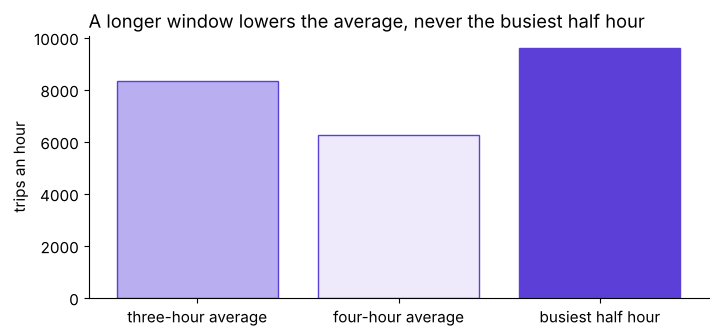

In [4]:
tph = (w.peak_trips / w.peak_online_hours)
idle = (1 - tph / 2.4).round(2)                                   # the share of an online hour with no rider
busiest = trips_an_hour * 1.15                                    # the busiest half hour's rate, unchanged
avg_four = 10_000_000 * 0.01 * 0.25 / 4
buffer_four = busiest / avg_four
drivers_four = avg_four / per_driver * buffer_four
cost_lakh = 1000 * 300 * 3 / 1e5
print(f"idle share like for like: {idle['before']} before, {idle['after']} after")
print(f"four hours: {avg_four:,.0f} trips an hour, buffer {buffer_four:.2f}, about {round(drivers_four, -2):,.0f} drivers")
print(f"a thousand idle drivers for three hours at the floor: up to Rs {cost_lakh:.0f} lakh an evening")
check("idle share about 0.21 before and 0.34 after", idle.tolist() == [0.21, 0.34])
check("the four-hour window leaves the answer at about 5,700", round(drivers_four, -2) == 5700)
check("Rs 9 lakh an evening for a thousand idle drivers", cost_lakh == 9)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(["three-hour average", "four-hour average", "busiest half hour"], [trips_an_hour, avg_four, busiest],
       color=[LILAC, PALE, VIOLET], edgecolor=VIOLET)
ax.set_ylabel("trips an hour")
ax.set_title("A longer window lowers the average, never the busiest half hour", loc="left")
plt.show()

**What happened.** The answer is b: the busiest half hour asks for the same trips an hour
whatever the window's length, so the buffer grows as the average shrinks and the answer stays
about 5,700.

## Does each hire-grade answer keep its structure?

An interviewer hears the structure before the numbers. The cell holds each answer as data, one
part a line in the order it is spoken, and checks it against one of two orders: the one-slide
answer's (claim, evidence, caveat, action, with a cost and a signer in the action) and the
guesstimate's four steps (clarify, map, calculate, validate).

**Predict before you run.** Which part does transcript 2's weak answer speak first?

a) Clarify
b) Map
c) Calculate
d) Validate

  transcript 1, hire-grade: decision > claim > evidence > caveat > action > change my mind  ->  keeps the structure
        transcript 1, weak: method > evidence > evidence > action  ->  breaks the structure
  transcript 2, hire-grade: clarify > map > calculate > range > validate > decision  ->  keeps the structure
        transcript 2, weak: calculate  ->  breaks the structure
PASS the hire-grade recommendation keeps the one-slide order, with a cost and a signer
PASS the weak recommendation breaks it
PASS the hire-grade estimate runs the four steps in order
PASS the weak estimate starts at the calculation


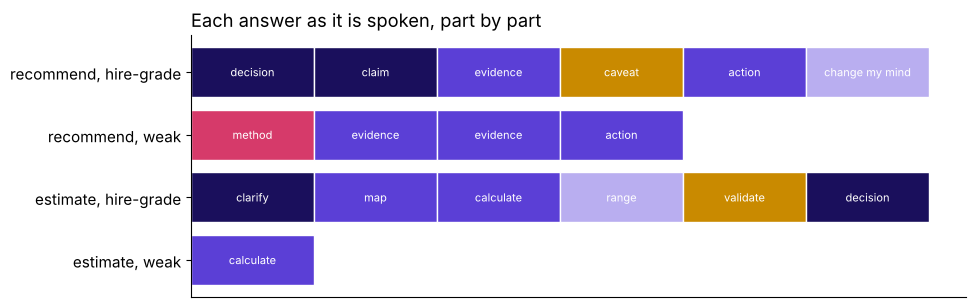

In [5]:
recommend_hire = [("decision", "you are deciding whether to keep, end or change the guarantee"),
                  ("claim", "the scheme is paying for online hours that carry no trips"),
                  ("evidence", "an online hour brought in Rs 260 of fares, down from Rs 314, at the same fare"),
                  ("caveat", "the monsoon ended in the same weeks, and last year's weeks are missing"),
                  ("action", "test it on half the drivers for six weeks at a rate fixed first; it saves Rs 58 lakh "
                             "to Rs 92.7 lakh over six weeks across the enrolled drivers; you sign"),
                  ("change my mind", "any zone's median wait more than half a minute above its level in the last "
                                     "six weeks, for two weeks running, stops the test early")]
recommend_weak = [("method", "so I looked at the dashboard"), ("evidence", "hours up, trips up, acceptance down"),
                  ("evidence", "bookings per driver-week is actually up"), ("action", "maybe pay per trip")]
estimate_hire = [("clarify", "one moment of the weekday evening peak, one product, a median wait under five minutes"),
                 ("map", "trips to serve an hour, over trips per online driver-hour, times a buffer"),
                 ("calculate", "8,330 over 1.68, times 1.15: about 5,700"),
                 ("range", "trips per person moves it from about 2,900 to 8,600"),
                 ("validate", "0.53 against 0.60 driver-hours per trip, pooled over both peaks: about 5,000 to "
                              "5,700, inside 2,900 to 8,600"),
                 ("decision", "the number sets the evening incentive")]
estimate_weak = [("calculate", "1 crore x 1 percent, over 2.4: about 41,700")]

ONE_SLIDE, FOUR_STEPS = ["claim", "evidence", "caveat", "action"], ["clarify", "map", "calculate", "validate"]
keeps = {}
for label, parts, wanted in [("transcript 1, hire-grade", recommend_hire, ONE_SLIDE),
                             ("transcript 1, weak", recommend_weak, ONE_SLIDE),
                             ("transcript 2, hire-grade", estimate_hire, FOUR_STEPS),
                             ("transcript 2, weak", estimate_weak, FOUR_STEPS)]:
    names = [name for name, _ in parts]
    places = [names.index(w) for w in wanted if w in names]          # where each wanted part is spoken
    action = dict(parts).get("action", "")
    priced = wanted != ONE_SLIDE or ("Rs" in action and "sign" in action)
    keeps[label] = len(places) == len(wanted) and places == sorted(places) and priced
    print(f"{label:>26}: {' > '.join(names)}  ->  {'keeps' if keeps[label] else 'breaks'} the structure")
check("the hire-grade recommendation keeps the one-slide order, with a cost and a signer", keeps["transcript 1, hire-grade"])
check("the weak recommendation breaks it", not keeps["transcript 1, weak"])
check("the hire-grade estimate runs the four steps in order", keeps["transcript 2, hire-grade"])
check("the weak estimate starts at the calculation", estimate_weak[0][0] == "calculate" and not keeps["transcript 2, weak"])

colours = {"decision": INK, "claim": INK, "evidence": VIOLET, "caveat": AMBER, "action": VIOLET,
           "change my mind": LILAC, "method": ROSE, "clarify": INK, "map": VIOLET, "calculate": VIOLET,
           "range": LILAC, "validate": AMBER}
fig, ax = plt.subplots(figsize=(10, 3.4))
rows = [("recommend, hire-grade", recommend_hire), ("recommend, weak", recommend_weak),
        ("estimate, hire-grade", estimate_hire), ("estimate, weak", estimate_weak)]
for r, (label, parts) in enumerate(rows):
    for k, (name, _) in enumerate(parts):
        ax.barh(r, 1, left=k, color=colours[name], edgecolor="white")
        ax.text(k + 0.5, r, name, ha="center", va="center", fontsize=8, color="white")
ax.set_yticks(range(len(rows)), [label for label, _ in rows])
ax.invert_yaxis()
ax.set_xticks([])
ax.set_title("Each answer as it is spoken, part by part", loc="left")
plt.show()

**What happened.** The answer is c: the weak estimate opens on a calculation, with no unit
clarified and no check, and the weak recommendation opens on method. Both hire-grade answers
speak their parts in the order the chapters taught, so the interviewer can follow each number
to the decision it serves.

## What does the AI-company variant's arithmetic say?

The third transcript is set at an invented coding-assistant company. Its hire-grade answer
says that at 32 percent accepted, if a fifth of accepted suggestions are deleted within a
week, only about 26 of every 100 suggestions shown survive. Both shares are shares of
suggestions, so they multiply; a share of characters would not.

**Predict before you run.** Of 100 suggestions shown, about how many survive a week?

a) 32
b) About 26
c) 20
d) About 6

of 100 shown: 32 accepted, about 26 still in the file a week later
PASS about 26 of 100 survive a week
PASS a fifth of the accepted is lost


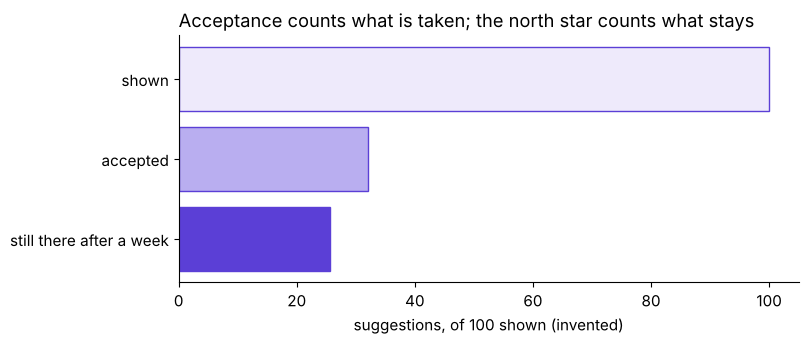

In [6]:
shown, accepted_share, kept_share = 100, 0.32, 0.8   # invented: of suggestions shown, the share accepted; of those, the share kept a week
accepted = shown * accepted_share
kept = accepted * kept_share
print(f"of {shown} shown: {accepted:.0f} accepted, about {kept:.0f} still in the file a week later")
check("about 26 of 100 survive a week", round(kept) == 26)
check("a fifth of the accepted is lost", round(accepted - kept, 1) == round(accepted * 0.2, 1))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(["shown", "accepted", "still there after a week"], [shown, accepted, kept], color=[PALE, LILAC, VIOLET],
        edgecolor=VIOLET)
ax.invert_yaxis()
ax.set_xlabel("suggestions, of 100 shown (invented)")
ax.set_title("Acceptance counts what is taken; the north star counts what stays", loc="left")
plt.show()

**What happened.** The answer is b: 32 accepted, about 26 still in the file a week later. The
answer keeps acceptance in the deck as a leading input and judges the team on what stays,
per paid seat, then names the check against last year's renewals that would change the call.

**Your turn.** Score your own spoken answer to one of the three questions on the room's seven
criteria, each 0, 1 or 2, as the scorecard on slide S90 sets them, and draw it. Type the lines
into the empty cell below, with your own scores in the blanks:

```python
mine = pd.Series({"Clarified the scope first": ___, "Named the denominator, or the unit, and the window": ___,
                  "Saw the trap": ___, "Sized it with a unit": ___, "Said what would change their mind": ___,
                  "Tied it to a decision and its cost": ___, "Gave the structure before the number": ___})
mine.plot.barh(color=VIOLET, xlim=(0, 2), title="My answer on the seven criteria")
plt.show()
check("every criterion scored 0, 1 or 2", mine.isin([0, 1, 2]).all())
print("the criterion to rehearse first:", mine.idxmin())
```

**The answers, one line each.**

1. Rs 313.5 to Rs 260.4 at a Rs 165 fare, printed Rs 314 and Rs 260; the 0.8 percent rise
   per driver-week sits with the 880 outside the idle tail, whose weeks rose 4 percent at an
   unchanged rate, while the idle tail's fell 12 percent and the joiners pulled the average
   down.
2. The chain gives about 5,700, the like-for-like check about 5,000, and the weak answer about
   41,700, seven times too many.
3. The idle share is about 0.21 before and 0.34 after; a four-hour window leaves about 5,700;
   a thousand idle drivers cost up to Rs 9 lakh an evening.
4. Both hire-grade answers keep their structure: the recommendation runs claim, evidence,
   caveat, action, and the estimate runs clarify, map, calculate, validate; both weak answers
   break it.
5. Of 100 suggestions shown, 32 are accepted and about 26 survive a week (invented).

### What will an interviewer ask about this, and what does a strong answer do?

**[S] A guesstimate: how many drivers must be online at the evening peak?** The structure
before the number, a unit beside every factor, the range with its driving factor, the check
like for like, and the cost of the decision the number sets.

**[D] The person who loses under your metric controls the meeting.** Concede their true part
first, keep their number in sight as a leading input, and agree before the meeting the test
and the result that decides it.